In [2]:
import pandas as pd

df = pd.read_excel("ADEI_Cleaning_Results.xlsx")
df.head(40)

,ticket_id,opened_at,channel,category,status,resolved_at,csat,invalid_opened_at,invalid_resolved_at,unexpected_resolved_at,conflicting_id,missing_ticket_id,missing_channel,missing_category,invalid_csat,resolution_minutes,negative_duration,exclusion_reason
0,TK-1001,2026-10-09 17:47:00,Email,Access,Resolved,2026-10-09 19:49:00,NaN,False,False,False,False,False,False,False,False,122.0,False,NaN
1,TK-1002,2026-10-07 09:16:00,Web,Billing,Resolved,2026-10-07 12:17:00,5.0,False,False,False,False,False,False,False,False,181.0,False,NaN
2,TK-1003,2026-10-05 15:14:00,WhatsApp,Access,Resolved,2026-10-05 17:36:00,2.0,False,False,False,False,False,False,False,False,142.0,False,NaN
3,TK-1004,2026-10-07 14:11:00,Web,Access,Resolved,2026-10-07 15:50:00,4.0,False,False,False,False,False,False,False,False,99.0,False,NaN
4,TK-1005,2026-10-09 12:59:00,Email,General,Resolved,2026-10-09 18:26:00,NaN,False,False,False,False,False,False,False,False,327.0,False,NaN
5,TK-1006,2026-10-08 08:27:00,Web,Technical,Resolved,2026-10-08 17:05:00,1.0,False,False,False,False,False,False,False,False,518.0,False,NaN
6,TK-1007,2026-10-07 08:23:00,Email,Technical,Open,NaT,NaN,False,False,False,False,False,False,False,False,NaN,False,NaN
7,TK-1008,2026-10-10 08:24:00,Web,Billing,Resolved,NaT,3.0,False,True,False,False,False,False,False,False,NaN,False,NaN
8,TK-1009,2026-10-11 14:33:00,Email,Billing,Resolved,2026-10-11 17:02:00,2.0,False,False,False,False,False,False,False,False,149.0,False,NaN
9,TK-1010,2026-10-08 09:36:00,WhatsApp,Billing,Resolved,2026-10-08 11:40:00,NaN,False,False,False,False,False,False,False,False,124.0,False,NaN


In [5]:
OUTPUT_FILE = "ADEI_Cleaning_Results.xlsx"

In [6]:
import pandas as pd
import numpy as np

file_path = "ADEI_Cleaning_Results.xlsx"
cleaned_df = pd.read_excel(file_path, sheet_name="Cleaned_Tickets")

In [7]:
SLA_HOURS = 24  

analysis_df = cleaned_df.copy()

analysis_df["opened_at"] = pd.to_datetime(
    analysis_df["opened_at"], errors="coerce"
)
analysis_df["resolved_at"] = pd.to_datetime(
    analysis_df["resolved_at"], errors="coerce"
)

analysis_df["resolution_hours"] = (
    analysis_df["resolved_at"] - analysis_df["opened_at"]
).dt.total_seconds() / 3600


In [8]:
# Only resolved tickets with a valid duration are used for SLA calculations
valid_duration = (
    analysis_df["status"].eq("Resolved")
    & analysis_df["resolution_hours"].notna()
    & (analysis_df["resolution_hours"] >= 0)
)

analysis_df["sla_breach"] = pd.NA
analysis_df.loc[valid_duration, "sla_breach"] = (
    analysis_df.loc[valid_duration, "resolution_hours"] > SLA_HOURS
)

overall_summary = pd.DataFrame({
    "Measure": [
        "Total ticket volume",
        "Resolved tickets with valid duration",
        "Median resolution time (hours)",
        "SLA breaches",
        "SLA breach rate (%)",
    ],
    "Value": [
        len(analysis_df),
        int(valid_duration.sum()),
        analysis_df.loc[valid_duration, "resolution_hours"].median(),
        int(analysis_df.loc[valid_duration, "sla_breach"].sum()),
        analysis_df.loc[valid_duration, "sla_breach"].mean() * 100,
    ],
})

display(overall_summary)

,Measure,Value
0,Total ticket volume,139.000000
1,Resolved tickets with valid duration,94.000000
2,Median resolution time (hours),4.966667
3,SLA breaches,1.000000
4,SLA breach rate (%),1.063830


Channel comparison


,channel,ticket_volume,valid_resolution_sample,median_resolution_hours,sla_breaches,sla_sample_size,sla_breach_rate_percent
0,Web,51,34,4.58,0,34,0.0
1,Email,47,34,5.55,0,34,0.0
2,WhatsApp,39,24,4.73,0,24,0.0
3,SMS,1,1,55.08,1,1,100.0
4,Unknown,1,1,8.60,0,1,0.0


Weekly trend


,week_starting,ticket_volume,valid_resolution_sample,median_resolution_hours,sla_breaches,sla_sample_size,sla_breach_rate_percent
0,2026-10-05,34,27,3.55,0,27,0.0
1,2026-10-12,35,20,4.78,0,20,0.0
2,2026-10-19,35,22,4.25,0,22,0.0
3,2026-10-26,35,25,7.10,1,25,4.0


Total cleaned tickets: 139
Tickets with valid resolution times: 94
SLA target used: 24 hours


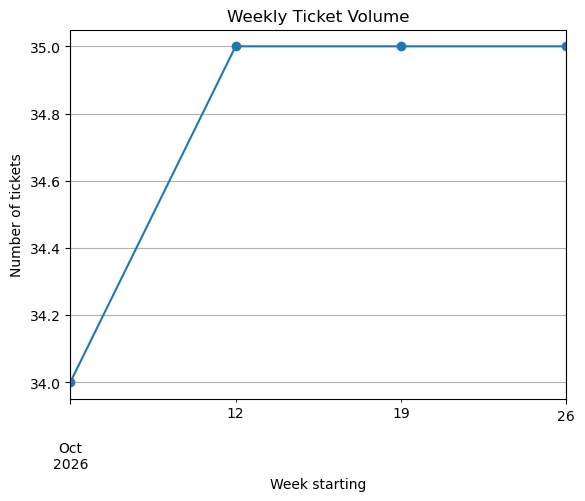

In [11]:
import pandas as pd
import numpy as np

# Load the cleaned data
file_path = "ADEI_Cleaning_Results.xlsx"
analysis_df = pd.read_excel(file_path, sheet_name="Cleaned_Tickets")

SLA_HOURS = 24  # Change this to the SLA target in your assessment

# Standardise channel labels, including WA and blank values
channel_mapping = {
    "email": "Email",
    "web": "Web",
    "whatsapp": "WhatsApp",
    "wa": "WhatsApp",
    "whats app": "WhatsApp",
    "sms": "SMS",
}

analysis_df["channel"] = (
    analysis_df["channel"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(channel_mapping)
    .fillna("Unknown")
)

# Make sure timestamps are datetime values
analysis_df["opened_at"] = pd.to_datetime(
    analysis_df["opened_at"], errors="coerce"
)
analysis_df["resolved_at"] = pd.to_datetime(
    analysis_df["resolved_at"], errors="coerce"
)

# Calculate resolution time in hours
analysis_df["resolution_hours"] = (
    analysis_df["resolved_at"] - analysis_df["opened_at"]
).dt.total_seconds() / 3600

# Include only resolved tickets with valid, non-negative durations
valid_duration = (
    analysis_df["status"].astype("string").str.strip().str.lower().eq("resolved")
    & analysis_df["resolution_hours"].notna()
    & analysis_df["resolution_hours"].ge(0)
)

analysis_df["valid_duration"] = valid_duration
analysis_df["sla_breach"] = False
analysis_df.loc[valid_duration, "sla_breach"] = (
    analysis_df.loc[valid_duration, "resolution_hours"] > SLA_HOURS
)

# Make a Monday week-start date for each ticket
analysis_df["week_start"] = (
    analysis_df["opened_at"].dt.to_period("W-SUN").dt.start_time
)

# Summarise each channel
channel_rows = []

for channel, group in analysis_df.groupby("channel", dropna=False):
    valid = group[group["valid_duration"]]

    channel_rows.append({
        "channel": channel,
        "ticket_volume": len(group),
        "valid_resolution_sample": len(valid),
        "median_resolution_hours": valid["resolution_hours"].median(),
        "sla_breaches": int(valid["sla_breach"].sum()),
        "sla_sample_size": len(valid),
        "sla_breach_rate_percent": (
            valid["sla_breach"].mean() * 100 if len(valid) > 0 else np.nan
        ),
    })

channel_summary = (
    pd.DataFrame(channel_rows)
    .sort_values("ticket_volume", ascending=False)
    .reset_index(drop=True)
)

print("Channel comparison")
display(channel_summary.round(2))

# Summarise each week
weekly_rows = []

for week, group in analysis_df.groupby("week_start", dropna=False):
    valid = group[group["valid_duration"]]

    weekly_rows.append({
        "week_starting": week,
        "ticket_volume": len(group),
        "valid_resolution_sample": len(valid),
        "median_resolution_hours": valid["resolution_hours"].median(),
        "sla_breaches": int(valid["sla_breach"].sum()),
        "sla_sample_size": len(valid),
        "sla_breach_rate_percent": (
            valid["sla_breach"].mean() * 100 if len(valid) > 0 else np.nan
        ),
    })

weekly_summary = (
    pd.DataFrame(weekly_rows)
    .sort_values("week_starting")
    .reset_index(drop=True)
)

print("Weekly trend")
display(weekly_summary.round(2))

# Plot weekly ticket volume
weekly_summary.plot(
    x="week_starting",
    y="ticket_volume",
    kind="line",
    marker="o",
    title="Weekly Ticket Volume",
    xlabel="Week starting",
    ylabel="Number of tickets",
    grid=True,
    legend=False,
)

# Print sample sizes for your report
print("Total cleaned tickets:", len(analysis_df))
print("Tickets with valid resolution times:", int(analysis_df["valid_duration"].sum()))
print("SLA target used:", SLA_HOURS, "hours")

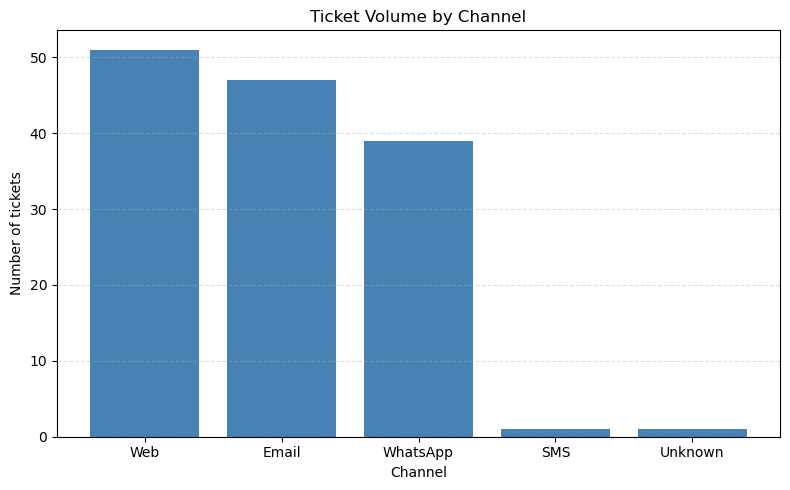

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(
    channel_summary["channel"],
    channel_summary["ticket_volume"],
    color="steelblue"
)
plt.title("Ticket Volume by Channel")
plt.xlabel("Channel")
plt.ylabel("Number of tickets")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

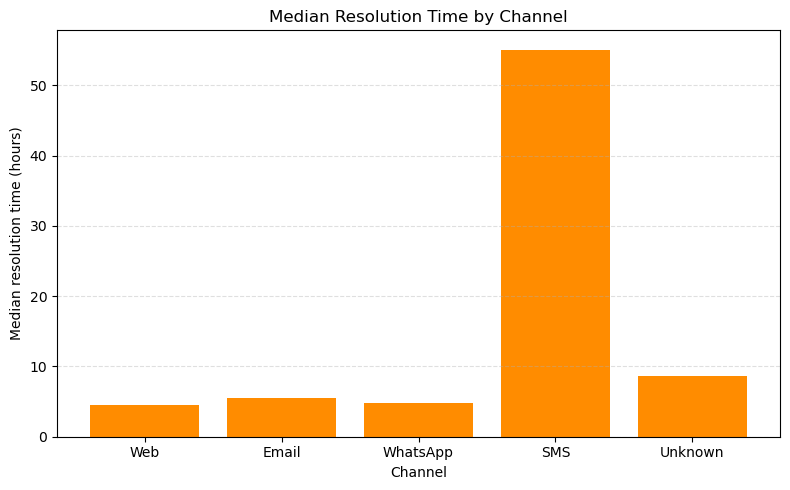

In [13]:
plt.figure(figsize=(8, 5))
plt.bar(
    channel_summary["channel"],
    channel_summary["median_resolution_hours"],
    color="darkorange"
)
plt.title("Median Resolution Time by Channel")
plt.xlabel("Channel")
plt.ylabel("Median resolution time (hours)")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Based on my tables:

1. Channel comparison: Web had the most tickets (51), followed by Email (47) and WhatsApp (39). Among tickets with valid resolution times, Web’s median was 4.58 hours (n = 34), compared with 5.55 hours for Email (n = 34) and 4.73 hours for WhatsApp (n = 24). SMS had a median of 55.08 hours, but that result is based on only one ticket (n = 1). The Unknown channel also had one ticket.
   
2. Weekly trend: Ticket volume was steady: 34 tickets in the week starting 5 October, then 35 in each of the next three weeks. The median resolution time was highest in the week starting 26 October, at 7.10 hours (n = 25 valid resolutions). That week had one SLA breach out of 25 tickets (4%) using the 24-hour SLA; the earlier weeks had none (n = 27, 20, and 22).
Recommended action: Review the single SMS ticket that took 55.08 hours to resolve to find out what caused the delay, then monitor more SMS tickets before deciding whether the channel needs a broader change.

Limitation: Resolution and SLA measures include only resolved tickets with valid timestamps (94 tickets overall). Unresolved tickets and records with missing or invalid timestamps are excluded. The SMS result comes from just one ticket, so it may not represent typical SMS performance.